<a href="https://colab.research.google.com/github/junelwc6-source/IBM-HR-Attrition-Analytics/blob/main/IBM_HR_Attrition_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


### 1. Project Overview

**Project Title:** Employee Attrition Analysis and Prediction

**BProblem Statement:**

How can employee data be analysed to identify key factors associated with employee attrition, predict employees' likelihood of leaving, and support targeted retention strategies and proactive workforce planning to reduce attrition and minimise staffing gaps?

**Dataset:**

IBM HR Analytics Employee Attrition Dataset, comprising five datasets covering employee demographics, compensation, performance, work experience and employment status.



## 2. Data Loading and Understanding

### Objective

To load and examine the five IBM HR Analytics datasets, understand their structure and identify the variables available for employee attrition analysis.

### Data Sources

The analysis uses five datasets:

1. **Employees** – Employee demographics, department and job role.
2. **Compensation** – Salary and compensation information.
3. **Performance** – Job satisfaction, work-life balance and performance indicators.
4. **Experience** – Employment tenure, work experience and career progression.
5. **Employment Status** – Employee attrition and overtime status.



In [107]:

import pandas as pd

# GitHub repository location
base_url = "https://raw.githubusercontent.com/junelwc6-source/IBM-HR-Attrition-Analytics/main/"

# Load datasets directly from GitHub
employees = pd.read_csv(base_url + "Employees.csv")
compensation = pd.read_csv(base_url + "Compensation.csv")
performance = pd.read_csv(base_url + "Performance.csv")
experience = pd.read_csv(base_url + "Experience.csv")
employment_status = pd.read_csv(
    base_url + "Employment%20Status.csv"
)

# Check datasets loaded successfully
print("Employees:", employees.shape)
print("Compensation:", compensation.shape)
print("Performance:", performance.shape)
print("Experience:", experience.shape)
print("Employment Status:", employment_status.shape)


Employees: (1470, 14)
Compensation: (1470, 7)
Performance: (1470, 7)
Experience: (1470, 8)
Employment Status: (1470, 3)


In [108]:

# Check data quality for all five datasets

datasets = {
    "Employees": employees,
    "Compensation": compensation,
    "Performance": performance,
    "Experience": experience,
    "Employment Status": status
}

for name, df in datasets.items():
    print("\n", name)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())



 Employees
Missing values: 5
Duplicate Employee IDs: 0

 Compensation
Missing values: 0
Duplicate Employee IDs: 0

 Performance
Missing values: 0
Duplicate Employee IDs: 0

 Experience
Missing values: 0
Duplicate Employee IDs: 0

 Employment Status
Missing values: 0
Duplicate Employee IDs: 0



## 3. Data Cleaning and Integration

### Objective

To identify and address data quality issues, validate employee records and merge the five datasets into a single dataset for analysis.

### Data Cleaning

The datasets were checked for missing values and data consistency. Five missing values were identified in the Age column of the Employees dataset. These were replaced with the median age of 36 to retain all employee records for descriptive analysis.


In [109]:

# Identify columns with missing values
print(employees.isnull().sum())

# Display records containing missing values
display(employees[employees.isnull().any(axis=1)])


EmployeeNumber      0
Age                 5
Gender              0
MaritalStatus       0
Education           0
EducationField      0
Department          0
JobRole             0
JobLevel            0
BusinessTravel      0
DistanceFromHome    0
EmployeeCount       0
Over18              0
StandardHours       0
dtype: int64


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,DistanceFromHome,EmployeeCount,Over18,StandardHours
5,8,NaN,Male,Single,2,Life Sciences,Research & Development,Laboratory Technician,1,Travel_Frequently,2,1,Y,80
27,35,NaN,Male,Married,4,Marketing,Sales,Sales Executive,2,Travel_Rarely,8,1,Y,80
134,177,NaN,Female,Married,1,Life Sciences,Human Resources,Human Resources,1,Travel_Rarely,25,1,Y,80
262,362,NaN,Male,Single,1,Technical Degree,Research & Development,Laboratory Technician,2,Travel_Rarely,2,1,Y,80
377,501,NaN,Female,Married,3,Life Sciences,Research & Development,Research Scientist,1,Travel_Rarely,2,1,Y,80


In [110]:

# Standardise gender values before data integration

employees["Gender"] = (
    employees["Gender"]
    .str.strip()
    .str.lower()
    .replace({
        "m": "male",
        "f": "female",
        "femal": "female"
    })
    .str.title()
)

# Verify cleaned gender categories
print(employees["Gender"].value_counts())


Gender
Male      882
Female    588
Name: count, dtype: int64


In [111]:

# Check the median age before cleaning
print("Median Age:", employees["Age"].median())

# Replace missing ages with the median age
employees["Age"] = employees["Age"].fillna(
    employees["Age"].median()
)

# Verify that no missing values remain
print("Missing Age values after cleaning:",
      employees["Age"].isnull().sum())


Median Age: 36.0
Missing Age values after cleaning: 0


### Data Cleaning – Missing Values

The initial data quality check identified five missing values in the Age column of the Employees dataset, representing approximately 0.34% of the 1,470 employee records.

The missing values were replaced using the median age to retain all employee records and minimise the influence of extreme values.

No duplicate Employee IDs were identified across the five datasets.

In [112]:

# Check whether Employee IDs match across all datasets

employee_ids = set(employees["EmployeeNumber"])

for name, df in datasets.items():
    ids = set(df["EmployeeNumber"])

    print(name)
    print("IDs missing from this dataset:",
          len(employee_ids - ids))
    print("Extra IDs in this dataset:",
          len(ids - employee_ids))
    print()


Employees
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Compensation
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Performance
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Experience
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Employment Status
IDs missing from this dataset: 0
Extra IDs in this dataset: 0



In [113]:

# Merge the five IBM HR datasets into one master dataframe

df = employees.merge(compensation, on="EmployeeNumber", validate="one_to_one")

df = df.merge(performance, on="EmployeeNumber", validate="one_to_one")

df = df.merge(experience, on="EmployeeNumber", validate="one_to_one")

df = df.merge(status, on="EmployeeNumber", validate="one_to_one")

# Check the merged dataset
print("Merged dataset shape:", df.shape)
print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

# Display the first 5 rows
display(df.head())


Merged dataset shape: (1470, 35)
Duplicate Employee IDs: 0
Total missing values: 0


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,...,WorkLifeBalance,NumCompaniesWorked,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,OverTime
0,1,41.0,Female,Single,2,Life Sciences,Sales,Sales Executive,2,Travel_Rarely,...,1,8,8,0,6,4,0,5,Yes,Yes
1,2,49.0,Male,Married,1,Life Sciences,Research & Development,Research Scientist,2,Travel_Frequently,...,3,1,10,3,10,7,1,7,No,No
2,4,37.0,Male,Single,2,Other,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,6,7,3,0,0,0,0,Yes,Yes
3,5,33.0,Female,Married,4,Life Sciences,Research & Development,Research Scientist,1,Travel_Frequently,...,3,1,8,3,8,7,3,0,No,Yes
4,7,27.0,Male,Married,1,Medical,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,9,6,3,2,2,2,2,No,No


### Data Integration

The five IBM HR Analytics datasets were merged using `EmployeeNumber` as the common identifier.

Prior to merging, data validation confirmed that all five datasets contained 1,470 unique Employee IDs, with no missing or additional IDs across the datasets.

A one-to-one merge was performed to combine employee demographics, compensation, performance, experience and employment status into a single dataset for subsequent analysis.

## 4. Overall Employee Attrition Analysis

### Objective

To establish the overall employee attrition rate as a baseline for comparing attrition patterns across departments and employee groups.

In [114]:

# Calculate overall employee attrition

total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()
employees_stayed = (df["Attrition"] == "No").sum()

overall_attrition_rate = (
    employees_left / total_employees * 100
)

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print(f"Overall Attrition Rate: {overall_attrition_rate:.2f}%")


Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Overall Attrition Rate: 16.12%


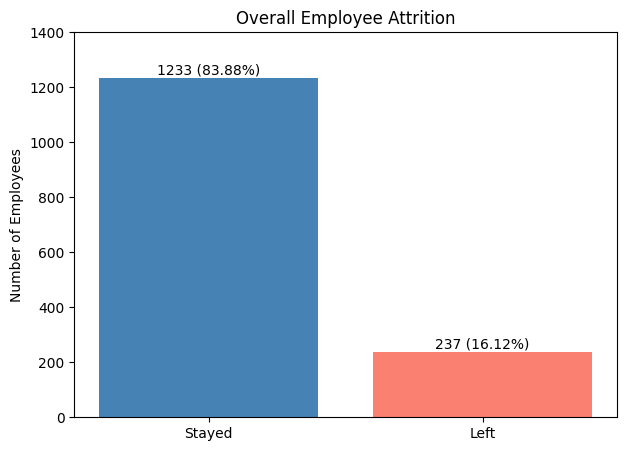

In [115]:

# Visualise overall employee attrition

import matplotlib.pyplot as plt

attrition_counts = [employees_stayed, employees_left]
labels = ["Stayed", "Left"]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    attrition_counts,
    color=["steelblue", "salmon"]
)

# Add employee counts and percentages
for bar, count in zip(bars, attrition_counts):
    percentage = count / total_employees * 100

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f"{count} ({percentage:.2f}%)",
        ha="center"
    )

plt.title("Overall Employee Attrition")
plt.ylabel("Number of Employees")
plt.ylim(0, 1400)

plt.show()



### Key Findings

The dataset contains 1,470 employees, of whom 237 (16.12%) left the organisation, while 1,233 (83.88%) remained.

The overall attrition rate of 16.12% provides a baseline for identifying departments and employee groups with higher attrition rates.

Further analysis will examine the factors associated with employee attrition and identify opportunities for targeted retention strategies.


## 5. Departmental Attrition Analysis

### Objective

To compare employee attrition rates across departments, identify departments with higher attrition and establish a baseline for further analysis of department-specific attrition factors.

In [116]:

# Calculate employee attrition by department

department_attrition = (
    df.groupby("Department")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

department_attrition["Attrition_Rate"] = (
    department_attrition["Employees_Left"] /
    department_attrition["Total_Employees"] * 100
).round(2)

department_attrition = department_attrition.sort_values(
    "Attrition_Rate", ascending=False
)

display(department_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


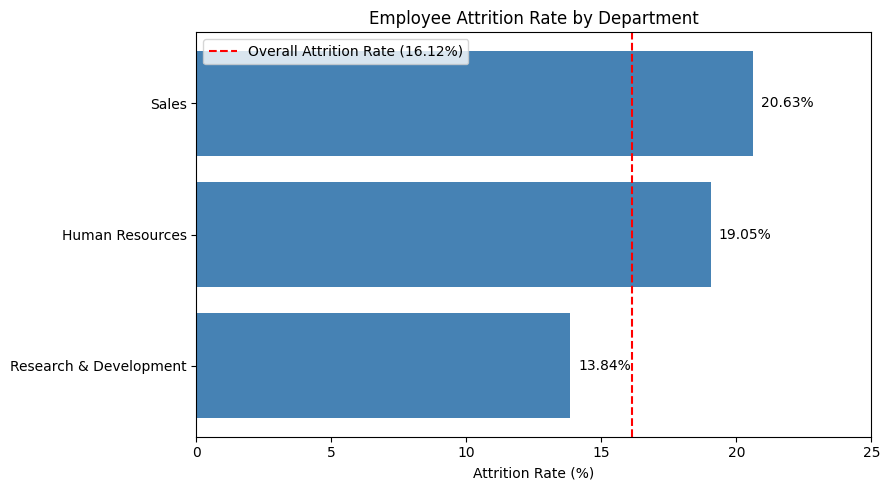

In [117]:

# Visualise attrition rates by department

plt.figure(figsize=(9, 5))

bars = plt.barh(
    department_attrition.index,
    department_attrition["Attrition_Rate"],
    color="steelblue"
)

# Add attrition rate labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

# Overall attrition rate as benchmark
plt.axvline(
    overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.xlim(0, 25)
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()



### Key Findings

Sales recorded the highest attrition rate at 20.63% (92 out of 446 employees), followed by Human Resources at 19.05% (12 out of 63 employees). Both departments exceeded the overall attrition rate of 16.12%.

Research & Development recorded the lowest attrition rate at 13.84%. However, it had the highest number of employees who left (133), reflecting its larger workforce.

These findings indicate that Sales and Human Resources have higher relative attrition rates, while Research & Development contributes the largest number of employee departures.

Further analysis will examine the factors associated with attrition within each department to identify potential areas for targeted retention strategies.




## 6. Key Attrition Factors by Department

### 6.1 Department Attrition by Age

**Objective:** To examine employee attrition across different age groups within each department and identify groups with higher attrition rates.

In [118]:

# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 29, 39, 49, float("inf")],
    labels=["Under 30", "30-39", "40-49", "50 and above"]
)

# Calculate attrition by department and age group
age_attrition = (
    df.groupby(["Department", "AgeGroup"], observed=True)["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

age_attrition["Attrition_Rate"] = (
    age_attrition["Employees_Left"] /
    age_attrition["Total_Employees"] * 100
).round(2)

display(age_attrition)


,Department,AgeGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Under 30,12,6,50.00
1,Human Resources,30-39,26,5,19.23
2,Human Resources,40-49,17,1,5.88
3,Human Resources,50 and above,8,0,0.00
4,Research & Development,Under 30,217,55,25.35
5,Research & Development,30-39,397,49,12.34
6,Research & Development,40-49,230,16,6.96
7,Research & Development,50 and above,117,13,11.11
8,Sales,Under 30,96,30,31.25
9,Sales,30-39,201,35,17.41


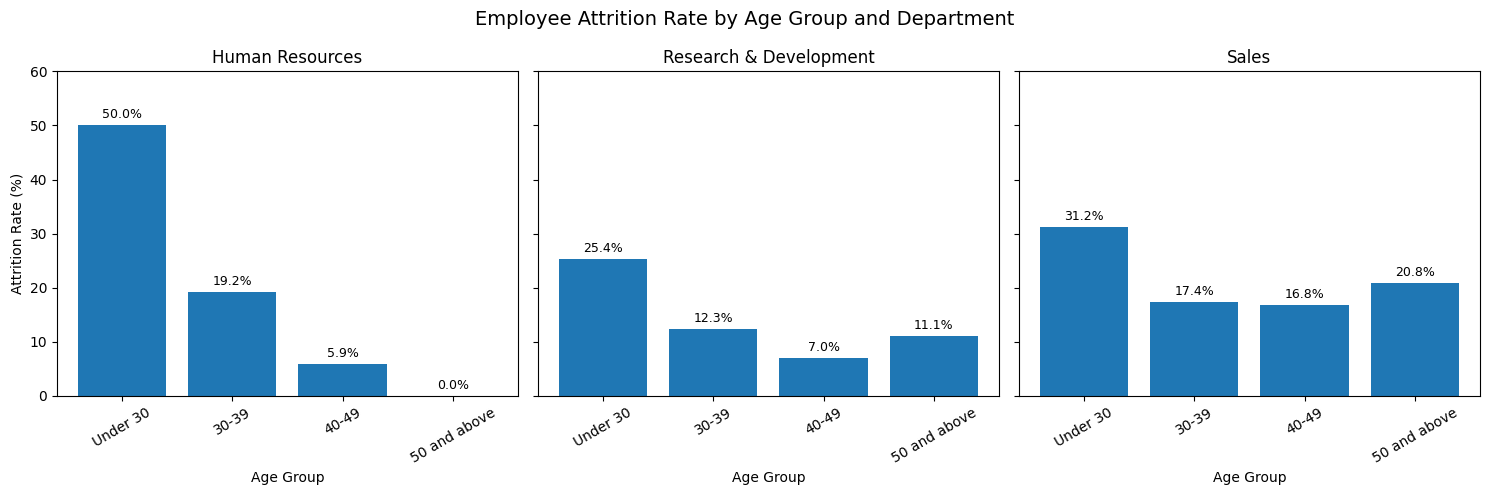

In [127]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = age_attrition[
        age_attrition["Department"] == dept
    ]

    bars = ax.bar(
        data["AgeGroup"].astype(str),
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Age Group")
    ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=30)

    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Age Group and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees under 30 recorded the highest attrition rate at 50.00% (6 out of 12 employees).
- **Research & Development:** Employees under 30 had the highest attrition rate at 25.35%, compared with 6.96% among employees aged 40–49.
- **Sales:** Employees under 30 recorded the highest attrition rate at 31.25%, followed by employees aged 50 and above at 20.83%.
- **Overall:** Employees under 30 consistently recorded the highest attrition rates across all three departments, suggesting that younger employees may warrant further investigation in retention planning.

*Note: The Human Resources department has a relatively small number of employees under 30 (12 employees), so its attrition rate should be interpreted cautiously.*


### 6.2 Department Attrition by Job Role

**Objective:** To compare employee attrition rates across different job roles within each department and identify roles with higher attrition rates.

In [121]:

# Calculate attrition by department and job role
role_attrition = (
    df.groupby(["Department", "JobRole"])["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

role_attrition["Attrition_Rate"] = (
    role_attrition["Employees_Left"] /
    role_attrition["Total_Employees"] * 100
).round(2)

# Sort results by department and attrition rate
role_attrition = role_attrition.sort_values(
    ["Department", "Attrition_Rate"],
    ascending=[True, False]
)

display(role_attrition)


,Department,JobRole,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Human Resources,52,12,23.08
1,Human Resources,Manager,11,0,0.00
3,Research & Development,Laboratory Technician,259,62,23.94
7,Research & Development,Research Scientist,292,47,16.10
5,Research & Development,Manufacturing Director,145,10,6.90
2,Research & Development,Healthcare Representative,131,9,6.87
4,Research & Development,Manager,54,3,5.56
6,Research & Development,Research Director,80,2,2.50
10,Sales,Sales Representative,83,33,39.76
9,Sales,Sales Executive,326,57,17.48


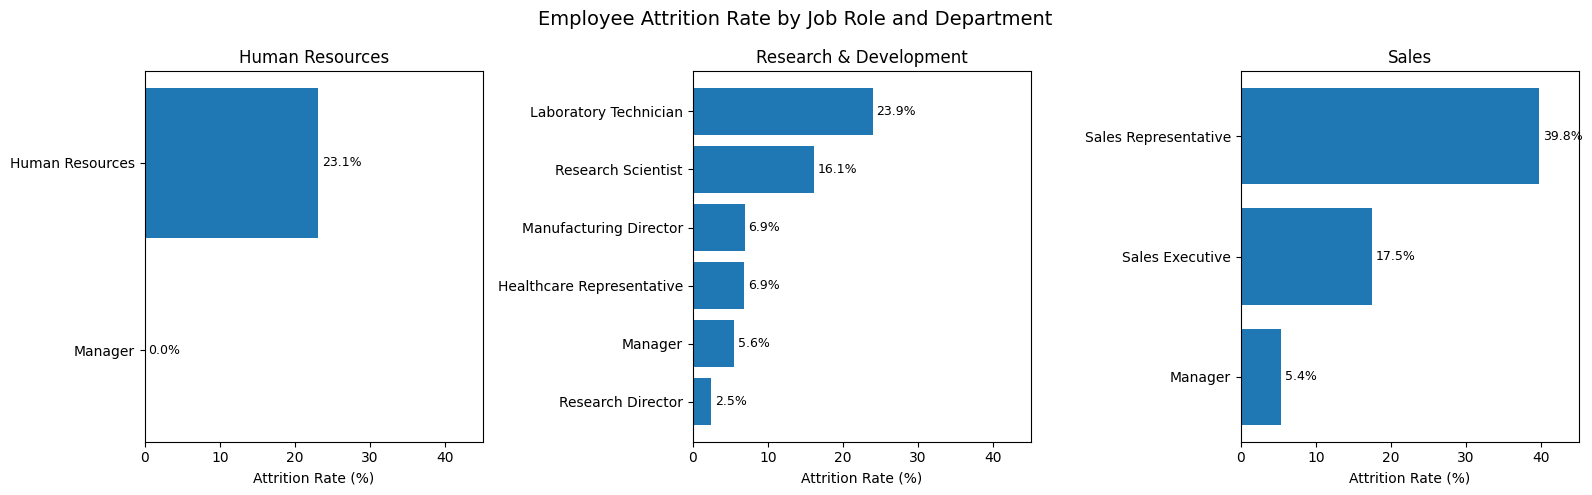

In [122]:

import matplotlib.pyplot as plt

# Create separate horizontal bar charts for each department
departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, dept in zip(axes, departments):
    data = role_attrition[
        role_attrition["Department"] == dept
    ].sort_values("Attrition_Rate")

    bars = ax.barh(
        data["JobRole"],
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Attrition Rate (%)")
    ax.set_xlim(0, 45)

    # Add percentage labels
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va="center",
            fontsize=9
        )

fig.suptitle(
    "Employee Attrition Rate by Job Role and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()




**Key Findings**

- **Human Resources:** HR staff recorded an attrition rate of 23.08% (12 out of 52 employees), while no attrition was recorded among the 11 Managers.
- **Research & Development:** Laboratory Technicians had the highest attrition rate at 23.94% (62 out of 259 employees), followed by Research Scientists at 16.10%.
- **Sales:** Sales Representatives recorded the highest attrition rate at 39.76% (33 out of 83 employees), compared with 17.48% among Sales Executives.
- **Overall:** Sales Representatives and Laboratory Technicians stand out as employee groups that may warrant further investigation and targeted retention strategies.


### 6.3 Department Attrition by Monthly Income

**Objective:** To examine the relationship between monthly income and employee attrition within each department and identify income groups with higher attrition rates.

Employees are categorised into four department-specific income groups: Low, Lower-Middle, Upper-Middle and High.

In [123]:

# Create monthly income groups within each department
income_labels = ["Low", "Lower-Middle", "Upper-Middle", "High"]

df["IncomeGroup"] = (
    df.groupby("Department")["MonthlyIncome"]
    .transform(
        lambda x: pd.qcut(
            x.rank(method="first"),
            q=4,
            labels=income_labels
        )
    )
)

# Calculate attrition by department and income group
income_attrition = (
    df.groupby(["Department", "IncomeGroup"], observed=True)["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

income_attrition["Attrition_Rate"] = (
    income_attrition["Employees_Left"] /
    income_attrition["Total_Employees"] * 100
).round(2)

display(income_attrition)


,Department,IncomeGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Low,16,6,37.50
1,Human Resources,Lower-Middle,16,4,25.00
2,Human Resources,Upper-Middle,15,0,0.00
3,Human Resources,High,16,2,12.50
4,Research & Development,Low,241,65,26.97
5,Research & Development,Lower-Middle,240,36,15.00
6,Research & Development,Upper-Middle,240,17,7.08
7,Research & Development,High,240,15,6.25
8,Sales,Low,112,35,31.25
9,Sales,Lower-Middle,111,17,15.32


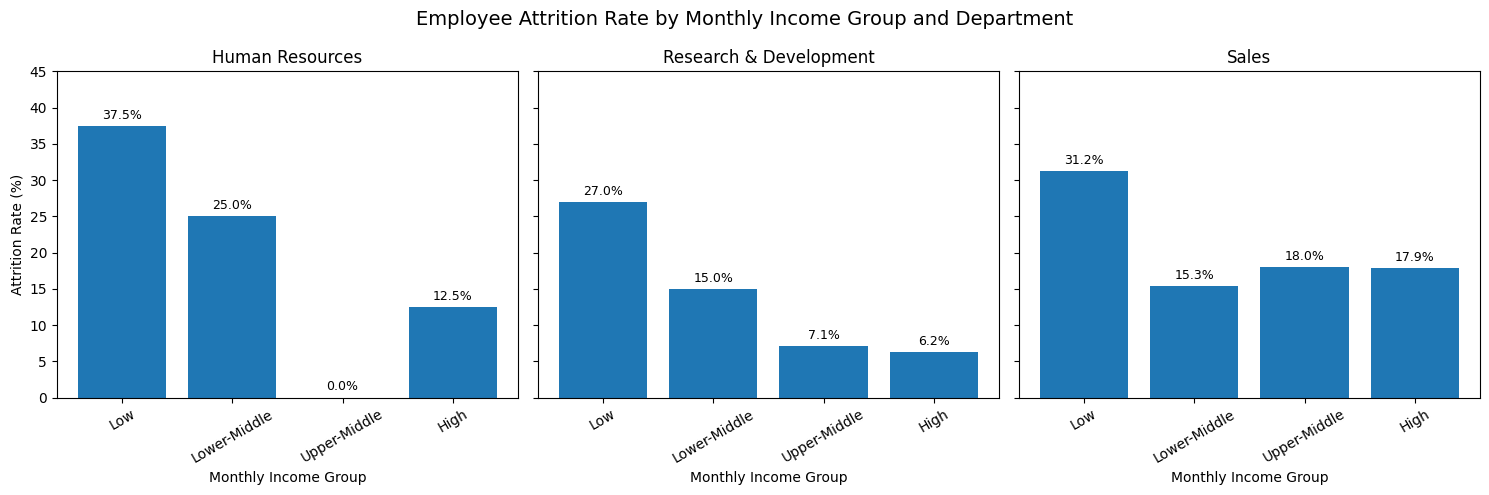

In [128]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

income_order = ["Low", "Lower-Middle", "Upper-Middle", "High"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = income_attrition[
        income_attrition["Department"] == dept
    ].set_index("IncomeGroup").reindex(income_order)

    bars = ax.bar(
        income_order,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Monthly Income Group")
    ax.set_ylim(0, 45)
    ax.tick_params(axis="x", rotation=30)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Monthly Income Group and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** The Low Income group recorded the highest attrition rate at 37.50% (6 out of 16 employees), followed by the Lower-Middle group at 25.00%.
- **Research & Development:** Attrition was highest in the Low Income group at 26.97%, declining to 6.25% in the High Income group.
- **Sales:** The Low Income group recorded the highest attrition rate at 31.25%, while the other income groups ranged from 15.32% to 18.02%.
- **Overall:** Lower-income employees consistently showed higher attrition across all three departments, suggesting that compensation-related factors warrant further investigation.

*Note: Income groups are based on department-specific quartiles. The findings show associations, not evidence that lower income causes attrition. The relatively small HR groups should also be interpreted cautiously.*


### 6.4 Department Attrition by Total Working Years

**Objective:** To examine employee attrition across different levels of total working experience within each department and identify whether less-experienced employees have higher attrition rates.

In [125]:

# Create total working experience groups
experience_labels = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "More than 20 years"
]

df["ExperienceGroup"] = pd.cut(
    df["TotalWorkingYears"],
    bins=[-1, 2, 5, 10, 20, float("inf")],
    labels=experience_labels
)

# Calculate attrition by department and experience group
experience_attrition = (
    df.groupby(
        ["Department", "ExperienceGroup"],
        observed=True
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

experience_attrition["Attrition_Rate"] = (
    experience_attrition["Employees_Left"] /
    experience_attrition["Total_Employees"] * 100
).round(2)

display(experience_attrition)


,Department,ExperienceGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,0-2 years,6,5,83.33
1,Human Resources,3-5 years,6,1,16.67
2,Human Resources,6-10 years,29,4,13.79
3,Human Resources,11-20 years,10,1,10.00
4,Human Resources,More than 20 years,12,1,8.33
5,Research & Development,0-2 years,83,31,37.35
6,Research & Development,3-5 years,123,21,17.07
7,Research & Development,6-10 years,396,54,13.64
8,Research & Development,11-20 years,221,19,8.60
9,Research & Development,More than 20 years,138,8,5.80


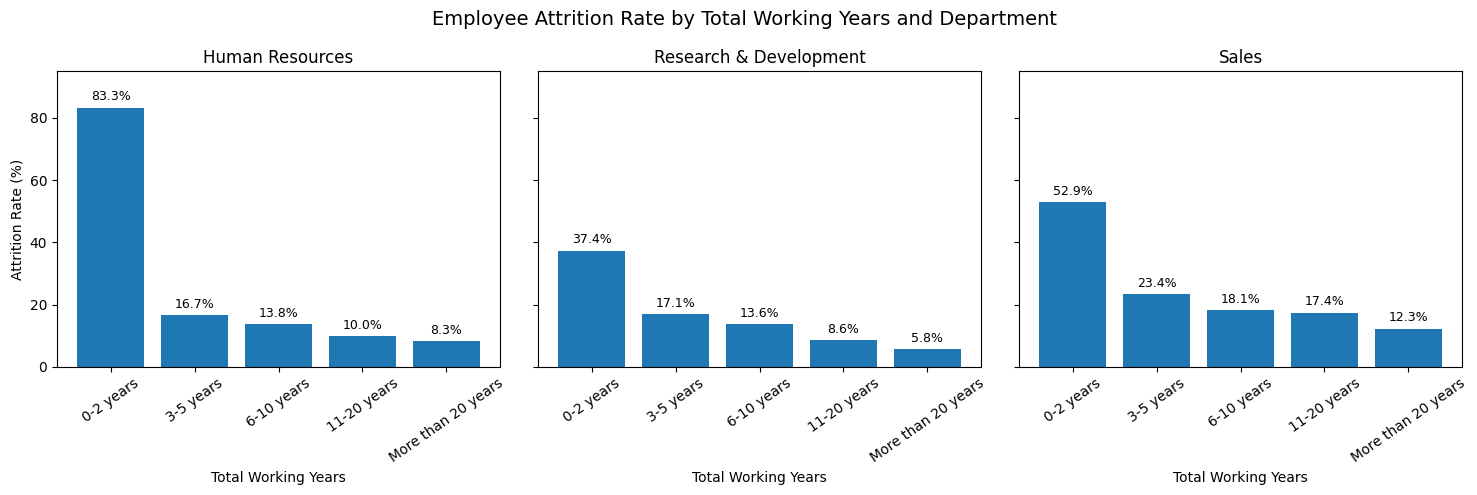

In [129]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        experience_attrition[
            experience_attrition["Department"] == dept
        ]
        .set_index("ExperienceGroup")
        .reindex(experience_labels)
    )

    bars = ax.bar(
        experience_labels,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Total Working Years")
    ax.set_ylim(0, 95)
    ax.tick_params(axis="x", rotation=35)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Total Working Years and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees with 0–2 years of working experience recorded the highest attrition rate at 83.33% (5 out of 6 employees), compared with 8.33% among those with more than 20 years of experience.
- **Research & Development:** Attrition was highest among employees with 0–2 years of experience at 37.35%, declining to 5.80% among those with more than 20 years of experience.
- **Sales:** Employees with 0–2 years of experience recorded the highest attrition rate at 52.94%, compared with 12.28% among those with more than 20 years of experience.
- **Overall:** Employees with less working experience consistently showed higher attrition across all three departments. This suggests that early-career employees may be an important group for HR to investigate when developing retention strategies.

*Note: The HR department has only 6 employees in the 0–2 years experience group, so its high attrition rate should be interpreted cautiously. Total working experience is different from tenure with the current organisation.*


### 6.5 Department Attrition by Years Since Last Promotion

**Objective:** To examine the relationship between years since last promotion and employee attrition across departments, and identify whether longer periods without promotion are associated with higher attrition rates.

In [130]:

# Create promotion groups
promotion_labels = [
    "0 years",
    "1-2 years",
    "3-5 years",
    "More than 5 years"
]

df["PromotionGroup"] = pd.cut(
    df["YearsSinceLastPromotion"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=promotion_labels
)

# Calculate attrition by department and promotion group
promotion_attrition = (
    df.groupby(
        ["Department", "PromotionGroup"],
        observed=True
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

promotion_attrition["Attrition_Rate"] = (
    promotion_attrition["Employees_Left"] /
    promotion_attrition["Total_Employees"] * 100
).round(2)

display(promotion_attrition)


,Department,PromotionGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,0 years,24,6,25.00
1,Human Resources,1-2 years,25,5,20.00
2,Human Resources,3-5 years,9,1,11.11
3,Human Resources,More than 5 years,5,0,0.00
4,Research & Development,0 years,379,65,17.15
5,Research & Development,1-2 years,346,42,12.14
6,Research & Development,3-5 years,102,8,7.84
7,Research & Development,More than 5 years,134,18,13.43
8,Sales,0 years,178,39,21.91
9,Sales,1-2 years,145,29,20.00


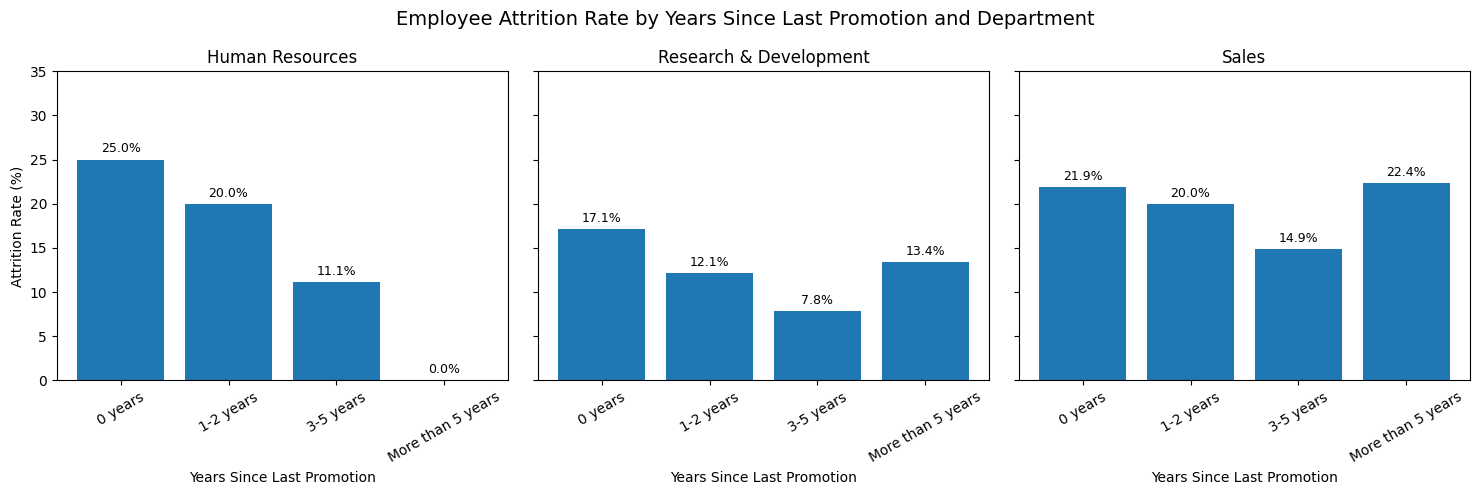

In [131]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        promotion_attrition[
            promotion_attrition["Department"] == dept
        ]
        .set_index("PromotionGroup")
        .reindex(promotion_labels)
    )

    bars = ax.bar(
        promotion_labels,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Years Since Last Promotion")
    ax.set_ylim(0, 35)
    ax.tick_params(axis="x", rotation=30)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Years Since Last Promotion and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees in the 0-year group recorded the highest attrition rate at 25.00% (6 out of 24 employees). No attrition was recorded among the 5 employees in the more-than-5-years group.
- **Research & Development:** The 0-year group had the highest attrition rate at 17.15%, followed by employees with more than 5 years since their last promotion at 13.43%.
- **Sales:** Employees with more than 5 years since their last promotion recorded the highest attrition rate at 22.37%, slightly above the 0-year group at 21.91%.
- **Overall:** There is no consistent relationship between years since last promotion and attrition across the three departments. Career progression may warrant further investigation alongside other factors such as job satisfaction and total working experience.

*Note: The 0-year category may include employees who have never been promoted. Small employee groups, particularly in Human Resources, should be interpreted cautiously.*


### 6.6 Department Attrition by Performance Rating

**Objective:** To examine the relationship between employee performance ratings and attrition across departments, and identify whether attrition rates differ between performance levels.

In [132]:

# Calculate attrition by department and performance rating
performance_attrition = (
    df.groupby(
        ["Department", "PerformanceRating"]
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

performance_attrition["Attrition_Rate"] = (
    performance_attrition["Employees_Left"] /
    performance_attrition["Total_Employees"] * 100
).round(2)

# Sort results by department and performance rating
performance_attrition = performance_attrition.sort_values(
    ["Department", "PerformanceRating"]
)

display(performance_attrition)


,Department,PerformanceRating,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,3,54,11,20.37
1,Human Resources,4,9,1,11.11
2,Research & Development,3,805,107,13.29
3,Research & Development,4,156,26,16.67
4,Sales,3,385,82,21.30
5,Sales,4,61,10,16.39


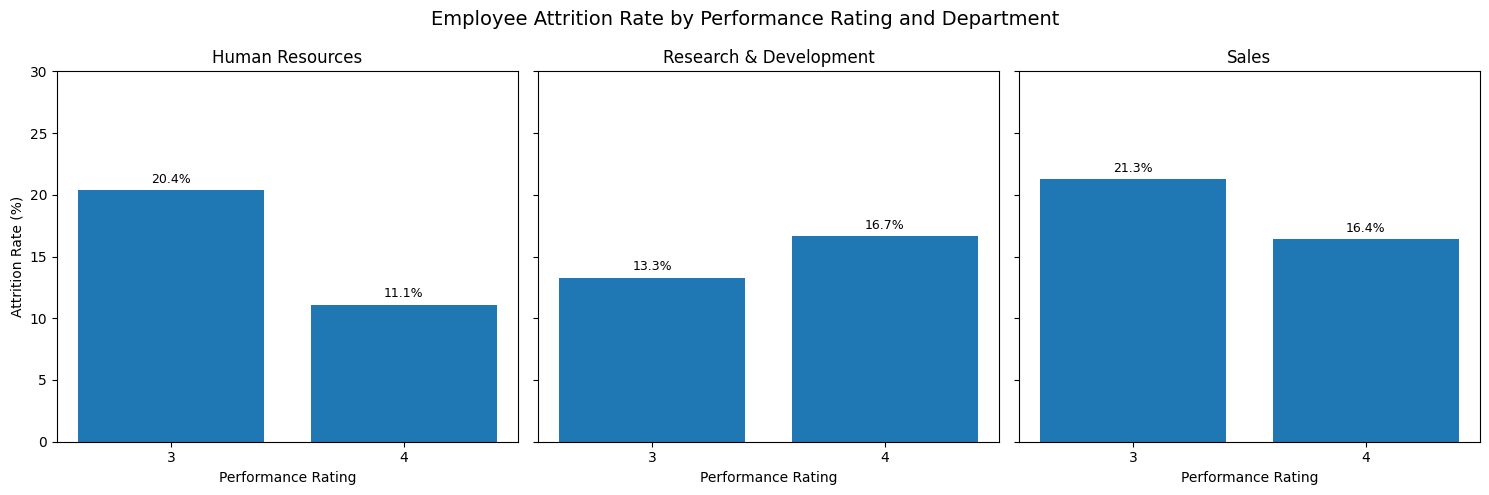

In [133]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = performance_attrition[
        performance_attrition["Department"] == dept
    ].sort_values("PerformanceRating")

    bars = ax.bar(
        data["PerformanceRating"].astype(str),
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Performance Rating")
    ax.set_ylim(0, 30)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Performance Rating and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees with Performance Rating 3 recorded a higher attrition rate (20.37%) than those with Rating 4 (11.11%).
- **Research & Development:** Employees with Rating 4 had a slightly higher attrition rate (16.67%) than those with Rating 3 (13.29%).
- **Sales:** Employees with Rating 3 recorded a higher attrition rate (21.30%) compared with those with Rating 4 (16.39%).
- **Overall:** Performance Rating does not show a consistent relationship with attrition across departments. The findings suggest that higher-rated employees are not necessarily less likely to leave.

*Note: The dataset contains only Performance Ratings 3 and 4. The small number of HR employees with Rating 4 (9 employees) should also be considered when interpreting the results.*


### 6.7 Department Attrition by Job Satisfaction

**Objective:** To examine the relationship between employee job satisfaction and attrition across departments, and identify whether employees with lower job satisfaction have higher attrition rates.

In [134]:

# Define job satisfaction levels
satisfaction_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

satisfaction_order = [
    "Low", "Medium", "High", "Very High"
]

# Create descriptive satisfaction categories
df["SatisfactionGroup"] = (
    df["JobSatisfaction"].map(satisfaction_labels)
)

# Calculate attrition by department and job satisfaction
satisfaction_attrition = (
    df.groupby(
        ["Department", "SatisfactionGroup"]
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

satisfaction_attrition["Attrition_Rate"] = (
    satisfaction_attrition["Employees_Left"] /
    satisfaction_attrition["Total_Employees"] * 100
).round(2)

# Arrange results in satisfaction order
satisfaction_attrition["SatisfactionGroup"] = pd.Categorical(
    satisfaction_attrition["SatisfactionGroup"],
    categories=satisfaction_order,
    ordered=True
)

satisfaction_attrition = satisfaction_attrition.sort_values(
    ["Department", "SatisfactionGroup"]
)

display(satisfaction_attrition)


,Department,SatisfactionGroup,Total_Employees,Employees_Left,Attrition_Rate
1,Human Resources,Low,11,5,45.45
2,Human Resources,Medium,20,2,10.00
0,Human Resources,High,15,3,20.00
3,Human Resources,Very High,17,2,11.76
5,Research & Development,Low,192,38,19.79
6,Research & Development,Medium,174,24,13.79
4,Research & Development,High,300,43,14.33
7,Research & Development,Very High,295,28,9.49
9,Sales,Low,86,23,26.74
10,Sales,Medium,86,20,23.26


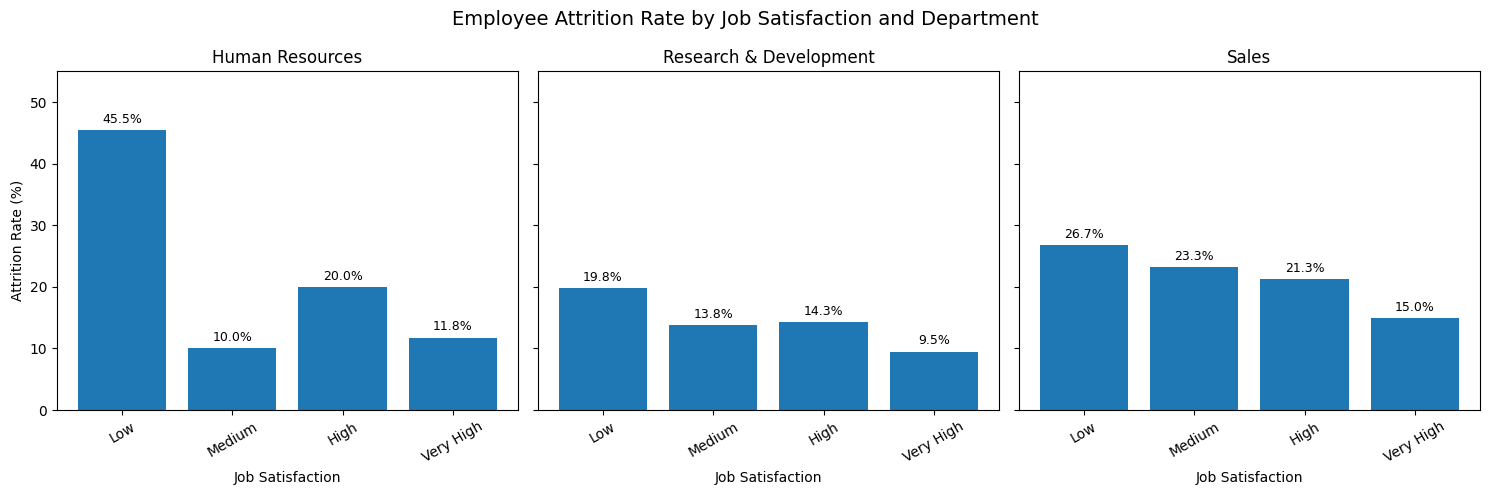

In [135]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        satisfaction_attrition[
            satisfaction_attrition["Department"] == dept
        ]
        .set_index("SatisfactionGroup")
        .reindex(satisfaction_order)
    )

    bars = ax.bar(
        satisfaction_order,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Job Satisfaction")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=30)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Job Satisfaction and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees with Low Job Satisfaction recorded the highest attrition rate at 45.45% (5 out of 11 employees), compared with 11.76% among those with Very High Job Satisfaction.
- **Research & Development:** Attrition was highest among employees with Low Job Satisfaction at 19.79%, compared with 9.49% among those with Very High Job Satisfaction.
- **Sales:** Employees with Low Job Satisfaction recorded the highest attrition rate at 26.74%, while those with Very High Job Satisfaction had the lowest rate at 14.97%.
- **Overall:** Low Job Satisfaction was associated with higher attrition across all three departments. This suggests that employee satisfaction and engagement may be important areas for HR to investigate when developing retention strategies.

*Note: The Human Resources Low Satisfaction group contains only 11 employees, so its attrition rate should be interpreted cautiously. The relationship does not establish that low satisfaction causes attrition.*


### 6.8 Department Attrition by Work-Life Balance

**Objective:** To examine the relationship between employee work-life balance and attrition across departments, and identify whether employees reporting poorer work-life balance experience higher attrition rates.

In [136]:

# Define work-life balance levels
wlb_labels = {
    1: "Bad",
    2: "Good",
    3: "Better",
    4: "Best"
}

wlb_order = ["Bad", "Good", "Better", "Best"]

# Create descriptive work-life balance categories
df["WorkLifeBalanceGroup"] = (
    df["WorkLifeBalance"].map(wlb_labels)
)

# Calculate attrition by department and work-life balance
wlb_attrition = (
    df.groupby(
        ["Department", "WorkLifeBalanceGroup"]
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

wlb_attrition["Attrition_Rate"] = (
    wlb_attrition["Employees_Left"] /
    wlb_attrition["Total_Employees"] * 100
).round(2)

# Arrange results in work-life balance order
wlb_attrition["WorkLifeBalanceGroup"] = pd.Categorical(
    wlb_attrition["WorkLifeBalanceGroup"],
    categories=wlb_order,
    ordered=True
)

wlb_attrition = wlb_attrition.sort_values(
    ["Department", "WorkLifeBalanceGroup"]
)

display(wlb_attrition)


,Department,WorkLifeBalanceGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Bad,4,0,0.00
3,Human Resources,Good,7,2,28.57
2,Human Resources,Better,42,9,21.43
1,Human Resources,Best,10,1,10.00
4,Research & Development,Bad,60,19,31.67
7,Research & Development,Good,235,32,13.62
6,Research & Development,Better,575,68,11.83
5,Research & Development,Best,91,14,15.38
8,Sales,Bad,16,6,37.50
11,Sales,Good,102,24,23.53


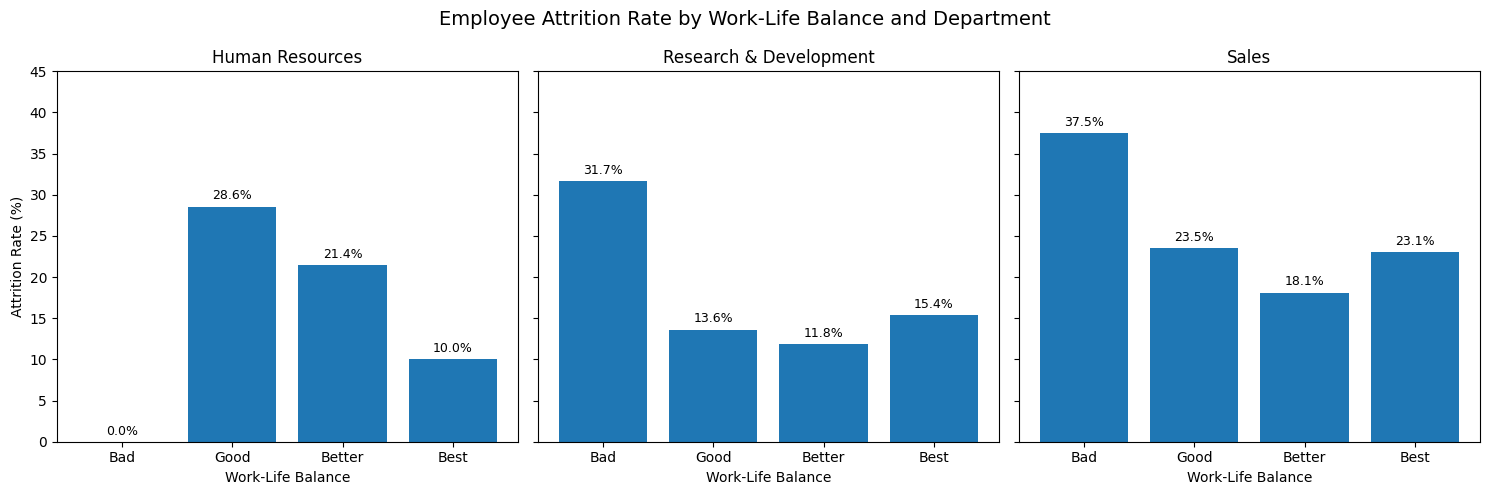

In [137]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        wlb_attrition[
            wlb_attrition["Department"] == dept
        ]
        .set_index("WorkLifeBalanceGroup")
        .reindex(wlb_order)
    )

    bars = ax.bar(
        wlb_order,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Work-Life Balance")
    ax.set_ylim(0, 45)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Work-Life Balance and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees reporting Good Work-Life Balance recorded the highest attrition rate at 28.57% (2 out of 7 employees), while no attrition was recorded among the 4 employees reporting Bad Work-Life Balance.
- **Research & Development:** Employees reporting Bad Work-Life Balance had the highest attrition rate at 31.67% (19 out of 60 employees), compared with 11.83% among those reporting Better Work-Life Balance.
- **Sales:** Employees reporting Bad Work-Life Balance recorded the highest attrition rate at 37.50% (6 out of 16 employees), compared with 18.12% among those reporting Better Work-Life Balance.
- **Overall:** Poor Work-Life Balance was associated with higher attrition in R&D and Sales. This suggests that workload management and employee well-being may warrant further investigation as part of HR retention planning.

*Note: The Human Resources Bad Work-Life Balance group contains only 4 employees, while the Sales group contains 16 employees. These smaller groups should be interpreted cautiously. The findings show associations rather than causation.*


### 6.9 Department Attrition by Overtime

**Objective:** To examine the relationship between overtime and employee attrition across departments, and identify whether employees who work overtime experience higher attrition rates.

In [138]:

# Calculate attrition by department and overtime
overtime_attrition = (
    df.groupby(["Department", "OverTime"])["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

overtime_attrition["Attrition_Rate"] = (
    overtime_attrition["Employees_Left"] /
    overtime_attrition["Total_Employees"] * 100
).round(2)

# Arrange results by department and overtime status
overtime_attrition = overtime_attrition.sort_values(
    ["Department", "OverTime"]
)

display(overtime_attrition)


,Department,OverTime,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,No,46,7,15.22
1,Human Resources,Yes,17,5,29.41
2,Research & Development,No,690,59,8.55
3,Research & Development,Yes,271,74,27.31
4,Sales,No,318,44,13.84
5,Sales,Yes,128,48,37.50


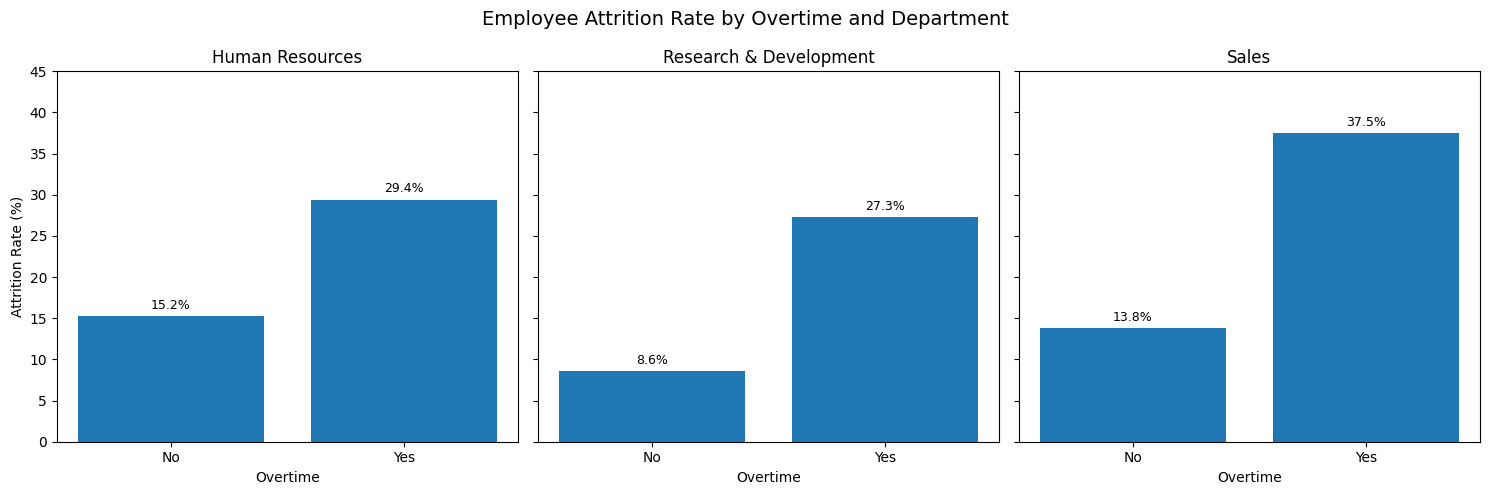

In [139]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        overtime_attrition[
            overtime_attrition["Department"] == dept
        ]
        .set_index("OverTime")
        .reindex(["No", "Yes"])
    )

    bars = ax.bar(
        ["No", "Yes"],
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Overtime")
    ax.set_ylim(0, 45)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Overtime and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees working overtime recorded an attrition rate of 29.41%, compared with 15.22% among those not working overtime.
- **Research & Development:** Employees working overtime had an attrition rate of 27.31%, compared with 8.55% among those not working overtime.
- **Sales:** Employees working overtime recorded the highest attrition rate at 37.50%, compared with 13.84% among those not working overtime.
- **Overall:** Overtime was consistently associated with higher attrition across all three departments, with the largest percentage-point difference observed in Sales. This suggests that workload management and overtime practices should be prioritised for further investigation when developing employee retention strategies.

*Note: These findings show an association between overtime and attrition, but do not establish that overtime causes employees to leave.*